<a href="https://colab.research.google.com/github/KarumeMaina/Flight_Price_Predictor/blob/main/Flight_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (replace 'Clean_Dataset.csv' with your exact filename)
df = pd.read_csv('Flight_Price_Prediction.csv')

# View the first 5 rows and check data types/missing values
display(df.head())
print(df.info())
print("\nMissing values:\n", df.isnull().sum())

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB
None

Missing values:
 Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0

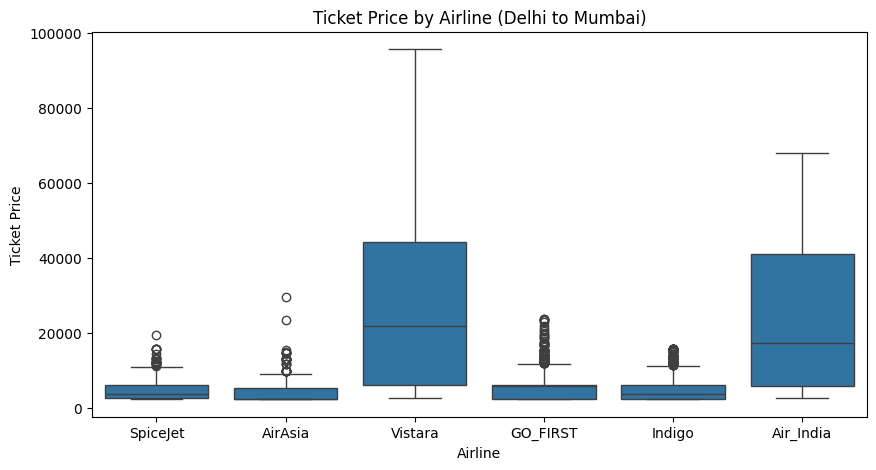

In [2]:
#Question 1: Does the price vary with Airlines for the same

# Filter data for a single popular route so the airline comparison is fair
route_df = df[(df['source_city'] == 'Delhi') & (df['destination_city'] == 'Mumbai')]

# Create a box plot comparing ticket prices by airline
plt.figure(figsize=(10, 5))
sns.boxplot(x='airline', y='price', data=route_df)
plt.title('Ticket Price by Airline (Delhi to Mumbai)')
plt.xlabel('Airline')
plt.ylabel('Ticket Price')
plt.show()

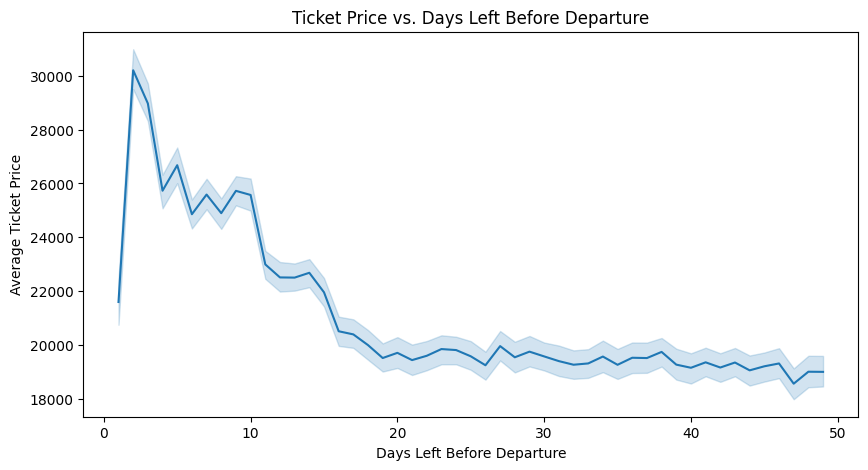

In [3]:
#Question 2: How is the price affected when tickets are bought just 1 or 2 days before departure?

plt.figure(figsize=(10, 5))
sns.lineplot(x='days_left', y='price', data=df)
plt.title('Ticket Price vs. Days Left Before Departure')
plt.xlabel('Days Left Before Departure')
plt.ylabel('Average Ticket Price')
plt.show()

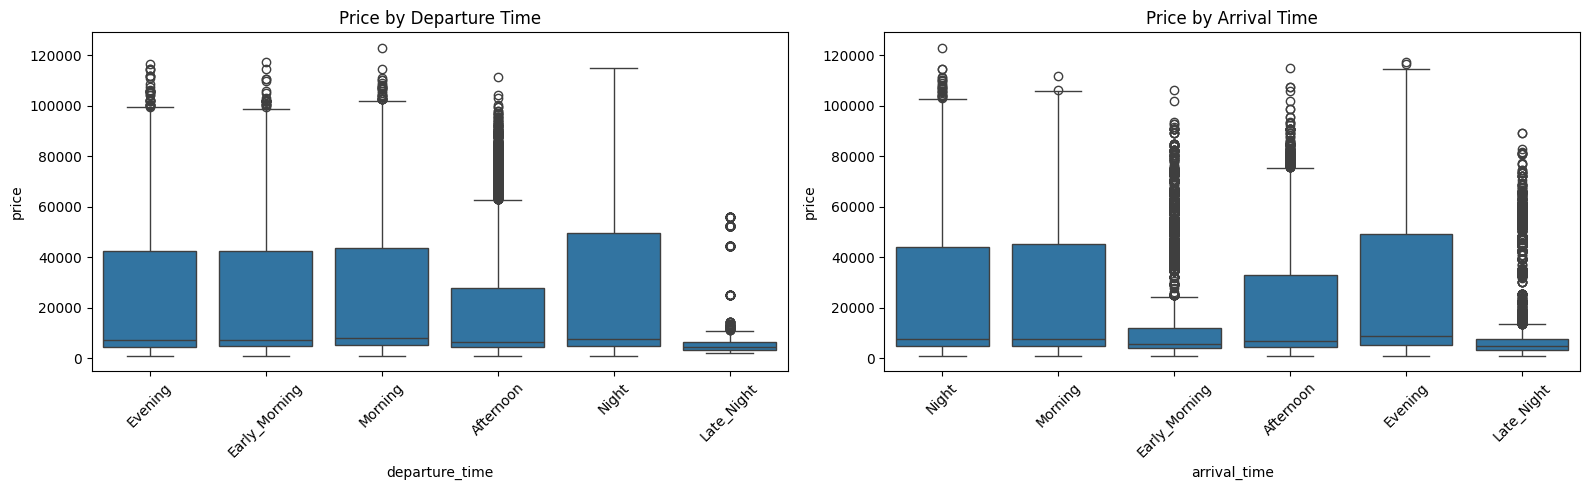

In [4]:
#Question 3: Does the ticket price change based on the departure time and arrival time?

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='departure_time', y='price', data=df, ax=axes[0])
axes[0].set_title('Price by Departure Time')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(x='arrival_time', y='price', data=df, ax=axes[1])
axes[1].set_title('Price by Arrival Time')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

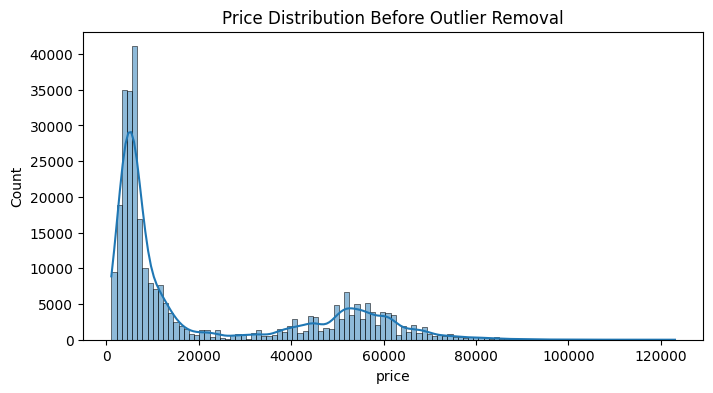

Original dataset rows: 300153
Cleaned dataset rows:  300030


In [5]:
#Checking Distribution & Removing Outliers

# 1. Visualize Price distribution before cleaning
plt.figure(figsize=(8, 4))
sns.histplot(df['price'], kde=True)
plt.title('Price Distribution Before Outlier Removal')
plt.show()

# 2. Remove outliers using the Interquartile Range (IQR) method
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create the new cleaned dataset
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()
print(f"Original dataset rows: {len(df)}")
print(f"Cleaned dataset rows:  {len(df_clean)}")

In [6]:
#Preparing Data for Linear Regression (Encoding)

# Drop ID/flight code columns that do not help generalize price predictions
cols_to_drop = [col for col in ['Unnamed: 0', 'flight'] if col in df_clean.columns]
df_model = df_clean.drop(columns=cols_to_drop)

# Convert text columns to 0s and 1s (drop_first=True prevents multicollinearity)
df_model = pd.get_dummies(df_model, drop_first=True, dtype=int)

# Separate Features (X) and Target variable (y = price)
X = df_model.drop('price', axis=1)
y = df_model['price']

In [7]:
#ing Models with Statsmodels (m1 vs. m2)

import statsmodels.api as sm
from sklearn.model_selection import train_test_split

# Split into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Build Model 1 (m1) with ALL features
X_train_sm = sm.add_constant(X_train) # Statsmodels requires an explicit constant (intercept)
m1 = sm.OLS(y_train, X_train_sm).fit()
print("=== MODEL 1 (ALL FEATURES) SUMMARY ===")
print(m1.summary())

# 2. Select Top 5 features using the largest absolute model coefficients
coeffs = m1.params.drop('const').abs().sort_values(ascending=False)
top_5_features = coeffs.head(5).index.tolist()
print("\nTop 5 Features Selected:", top_5_features)

# 3. Rebuild Model 2 (m2) using ONLY the Top 5 features
X_train_top5 = sm.add_constant(X_train[top_5_features])
m2 = sm.OLS(y_train, X_train_top5).fit()
print("\n=== MODEL 2 (TOP 5 FEATURES) SUMMARY ===")
print(m2.summary())

# 4. Compare R2 and Adjusted R2
print("\n=== MODEL COMPARISON ===")
print(f"Model 1 (All Features) -> R2: {m1.rsquared:.4f} | Adjusted R2: {m1.rsquared_adj:.4f}")
print(f"Model 2 (Top 5 Features) -> R2: {m2.rsquared:.4f} | Adjusted R2: {m2.rsquared_adj:.4f}")

=== MODEL 1 (ALL FEATURES) SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.913
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                 8.358e+04
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:52:07   Log-Likelihood:            -2.4550e+06
No. Observations:              240024   AIC:                         4.910e+06
Df Residuals:                  239993   BIC:                         4.910e+06
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

In [8]:
#Building & Comparing Scikit-Learn vs. Statsmodels

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Build and train Scikit-Learn model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Make predictions on the test set from both models
y_pred_sklearn = lr.predict(X_test)
y_pred_sm = m1.predict(sm.add_constant(X_test))

print("=== SCIKIT-LEARN VS STATSMODELS (TEST SET) ===")
print(f"Scikit-Learn R2: {r2_score(y_test, y_pred_sklearn):.4f}")
print(f"Statsmodels R2:  {r2_score(y_test, y_pred_sm):.4f}")
print(f"Scikit-Learn RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_sklearn)):.2f}")

=== SCIKIT-LEARN VS STATSMODELS (TEST SET) ===
Scikit-Learn R2: 0.9129
Statsmodels R2:  0.9129
Scikit-Learn RMSE: 6664.38
